# 高股息因子研究：从原始数据到组合回测
本教程是2026年10月新增教学练习，不是华泰历史业绩复现。
所有股票、财务数据和收益均为合成；生成器刻意植入弱因子关系，
因此正IC或正收益不能证明真实市场有效。无需下载或上传任何客户数据。
目标：理解字段、暴露、回归、IC、分组、交易成本与风险模型的区别。
依赖：numpy、pandas、scipy、statsmodels、matplotlib。Notebook已执行并保留输出。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr

OUT = Path('results')
OUT.mkdir(exist_ok=True)
SEED = 42
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

## 1. 先写研究假设与交易时间线
假设：分红较高且盈利质量较好的股票，可能有较好的未来相对收益。
固定规则：80只合成股票、4行业；月末观察、下一营业日开盘入场，
持有至下一次月度入场日；排名前20%等权做多。预设评分50%股息+50%质量。
此处BDay只是通用工作日，不是中国交易所日历；真实项目必须替换。
未来收益forward_return只用于评价，绝不用于构造当期分数。
教学收益代表已含分红的持有期简单总收益，不另加股息，避免重复计算。

In [2]:
def make_data(seed=42, n_stocks=80, n_months=96):
    rng = np.random.default_rng(seed)
    dates = pd.date_range('2018-01-31', periods=n_months, freq='ME')
    report_dates = pd.date_range('2017-06-30', periods=n_months+7, freq='ME')
    stocks = [f'S{i:03}' for i in range(n_stocks)]
    reports, quotes = [], []
    for i, stock in enumerate(stocks):
        industry = f'I{i % 4}'
        size = rng.normal()
        base_price = rng.uniform(15, 50)
        shares = np.exp(21.5 + size) / base_price
        base_yield = .015 + .009*(i % 4) + rng.uniform(0, .02)
        for rd in report_dates:
            reports.append([stock, rd, rd+pd.offsets.MonthEnd(2)+pd.Timedelta(days=10),
                            base_price*base_yield*rng.uniform(.7, 1.3),
                            rng.normal(.11, .045), rng.uniform(1, 4), rng.uniform(5, 18)])
        prices = base_price*np.exp(np.cumsum(rng.normal(0, .03, n_months)))
        for date, price in zip(dates, prices):
            quotes.append([date, stock, industry, price, shares*price])
    fundamentals = pd.DataFrame(reports, columns=['stock','report_period','available_date',
                                                  'dividend_ttm_ps','roe','eps_ttm','book_ps'])
    snapshots = []
    for stock, q in pd.DataFrame(quotes, columns=['date','stock','industry','price','market_cap']).groupby('stock'):
        f = fundamentals.loc[fundamentals.stock.eq(stock)].drop(columns='stock')
        snapshots.append(pd.merge_asof(q.sort_values('date'), f.sort_values('available_date'),
                                       left_on='date', right_on='available_date', direction='backward'))
    panel = pd.concat(snapshots).sort_values(['date','stock']).reset_index(drop=True)
    assert (panel.available_date <= panel.date).all()
    assert not panel.duplicated(['date','stock']).any()
    panel['entry_date'] = panel.date + pd.offsets.BDay(1)
    panel['exit_date'] = panel.date + pd.offsets.MonthEnd(1) + pd.offsets.BDay(1)
    return panel, fundamentals

panel, reports = make_data()
print('Synthetic stock-month rows:', len(panel))
print(panel[['date','stock','report_period','available_date','entry_date','exit_date']].head().to_string(index=False))

Synthetic stock-month rows: 7680
      date stock report_period available_date entry_date  exit_date
2018-01-31  S000    2017-10-31     2018-01-10 2018-02-01 2018-03-01
2018-01-31  S001    2017-10-31     2018-01-10 2018-02-01 2018-03-01
2018-01-31  S002    2017-10-31     2018-01-10 2018-02-01 2018-03-01
2018-01-31  S003    2017-10-31     2018-01-10 2018-02-01 2018-03-01
2018-01-31  S004    2017-10-31     2018-01-10 2018-02-01 2018-03-01


## 2. 原始因子和暴露怎么计算
$$DY_{i,t}=DPS^{known}_{i,t}/P_{i,t},\quad EP_{i,t}=EPS^{known}_{i,t}/P_{i,t},\quad BP_{i,t}=BPS^{known}_{i,t}/P_{i,t}$$
股息率是描述变量，不是下一期收益；EP/BP相当于正盈利、正净资产条件下PE/PB的倒数。
质量用ROE作简化代理，实际定义为净利润/平均净资产；本例ROE是合成已发布字段。
负盈利、负净资产要单独处理，不能把负PE最低的公司机械当便宜。
Size用log市值；行业暴露是0/1指示变量，而不是回归系数。

In [3]:
def zscore(s):
    sd = s.std(ddof=0)
    return (s-s.mean())/sd if sd > 1e-12 else s*0

def clip_z(s):
    return zscore(s.clip(s.quantile(.025), s.quantile(.975)))

def controls(g):
    dummy = pd.get_dummies(g.industry, prefix='sector', drop_first=True, dtype=float)
    return sm.add_constant(pd.concat([g[['size_z']], dummy], axis=1), has_constant='add')

def prepare_exposures(data):
    blocks = []
    for date, g in data.groupby('date', sort=True):
        g = g.copy()
        g['dy'] = g.dividend_ttm_ps/g.price
        g['ep'] = g.eps_ttm/g.price
        g['bp'] = g.book_ps/g.price
        g['size_z'] = clip_z(np.log(g.market_cap))
        g['dy_z'] = clip_z(g.dy)
        g['quality_z'] = clip_z(g.roe)
        C = controls(g)
        for source, dest in [('dy_z','dy_neutral'), ('quality_z','quality_neutral')]:
            fit = sm.OLS(g[source], C, missing='raise').fit()
            g[dest] = zscore(fit.resid)
            assert np.max(np.abs(C.to_numpy().T @ g[dest].to_numpy())) < 1e-8
        g['score'] = .5*g.dy_neutral + .5*g.quality_neutral
        blocks.append(g)
    return pd.concat(blocks).sort_values(['date','stock']).reset_index(drop=True)

panel = prepare_exposures(panel)
print(panel[['stock','dy','dy_z','roe','quality_z','size_z','dy_neutral','score']].head(8).round(4).to_string(index=False))

stock     dy    dy_z    roe  quality_z  size_z  dy_neutral   score
 S000 0.0339 -0.3576 0.1017    -0.2612  0.3247      0.9623  0.2383
 S001 0.0236 -1.1324 0.1504     0.8049 -1.8331     -0.7086  0.3663
 S002 0.0484  0.7429 0.1242     0.2320 -0.7925      0.6519  0.5316
 S003 0.0307 -0.5979 0.0139    -1.8896  2.0414     -3.0039 -2.7434
 S004 0.0350 -0.2757 0.1548     0.9021 -0.6114      1.3629  1.1123
 S005 0.0313 -0.5511 0.1283     0.3223 -0.1884     -0.2411  0.2261
 S006 0.0406  0.1493 0.1500     0.7962 -0.8418     -0.2930  0.3554
 S007 0.0474  0.6700 0.0567    -1.2457 -0.1933     -0.3152 -0.8971


## 3. 去极值、标准化、中性化不是同一件事
本例每个月只用当期股票：先将2.5%/97.5%以外值截尾，再z-score。
$$z_i=(x_i-\bar x)/\sigma_x$$
然后回归因子本身：$$z^{DY}_{i,t}=a_t+b_tSize_{i,t}+\sum_j c_{j,t}Industry_{ij}+u_{i,t}$$
u是对行业与规模调整后的因子值，不是收益率。再标准化u后用于打分。
OLS残差与控制变量在本截面正交，不等于经济独立、未来无相关或组合完全中性。
截距加K-1个行业dummy避免完全共线；statsmodels的OLS不会自动加截距。
同期全截面标准化不等于未来泄漏，因为此时各股票数据均已可见。

In [4]:
example = panel.loc[panel.date.eq(panel.date.min())].copy()
C = controls(example)
fit_neutral = sm.OLS(example.dy_z, C).fit()
print(pd.DataFrame({'raw_dy_z':example.dy_z,'explained_by_controls':fit_neutral.fittedvalues,
                    'residual':fit_neutral.resid}).head().round(4))
print('Maximum residual/control inner product:', np.max(np.abs(C.to_numpy().T @ fit_neutral.resid)))

   raw_dy_z  explained_by_controls  residual
0   -0.3576                -0.9533    0.5957
1   -1.1324                -0.6937   -0.4386
2    0.7429                 0.3394    0.4036
3   -0.5979                 1.2616   -1.8595
4   -0.2757                -1.1194    0.8437
Maximum residual/control inner product: 1.092459456231154e-13


## 4. 生成未来收益标签（仅教学）
下面显式植入弱因子关系和噪声。它不是“发现alpha”，而是检查流程能否识别已知结构。
实盘项目此处应读取执行后总收益，并保留真实退市、停牌和不可成交信息。
这里的价格快照和持有期收益分别合成，并非可成交的逐笔价格账本。

In [5]:
rng = np.random.default_rng(SEED+1)
panel['forward_return'] = np.nan
market = {}
for date, g in panel.groupby('date'):
    mkt = rng.normal(.004, .035)
    sector_shock = dict(zip(sorted(g.industry.unique()), rng.normal(0, .018, 4)))
    value = mkt + .0015*g.dy_neutral + .002*g.quality_neutral
    value = value + g.industry.map(sector_shock) + rng.normal(0, .055, len(g))
    panel.loc[g.index, 'forward_return'] = value
    market[date] = mkt
assert (panel.forward_return > -1).all()
panel['quintile'] = panel.groupby('date').score.transform(lambda x: pd.qcut(x.rank(method='first'),5,labels=False)+1)

## 5. 横截面收益回归：同一月份，80只股票
$$r_{i,t\to t+1}=a_{t+1}+f^{DY}_{t+1}z^{DY}_{i,t}+f^{Q}_{t+1}z^Q_{i,t}+f^{S}_{t+1}z^S_{i,t}+\sum_j f^j_{t+1}I_{ij}+\epsilon_{i,t+1}$$
X是本月已知特征；y是入场后下一持有期收益。这里使用原始标准化DY/Q并同时加控制，
而不是将每个因子分别中性化后仍把它们当相互独立。中性化后DY/Q之间仍可能相关。
横截面系数是本期实现的条件收益斜率，不是未来已知预测参数。
若想用系数预测，必须只用预测时已结算的历史截面估计值。

In [6]:
def return_design(g):
    return pd.concat([controls(g),g[['dy_z','quality_z']]],axis=1)

first = panel.loc[panel.date.eq(panel.date.min())]
X = return_design(first)
reg = sm.OLS(first.forward_return, X, missing='raise').fit(cov_type='HC3')
print('X shape:', X.shape, 'y shape:', first.forward_return.shape)
print(pd.DataFrame({'coefficient':reg.params,'HC3_t':reg.tvalues}).round(4))
print('Interpretation: dy_z coefficient is return change for +1 exposure unit, conditional on other X.')

X shape: (80, 7) y shape: (80,)
           coefficient   HC3_t
const           0.0259  1.4944
size_z         -0.0043 -0.6618
sector_I1      -0.0373 -1.7815
sector_I2      -0.0363 -1.6339
sector_I3      -0.0420 -1.4528
dy_z           -0.0088 -0.8213
quality_z      -0.0042 -0.6109
Interpretation: dy_z coefficient is return change for +1 exposure unit, conditional on other X.


## 6. 多个月份重复回归，为什么不只看一个t值
每个月跑一次，得到因子收益序列。可以对月度系数均值估计HAC标准误，
检查时间相关影响；单月HC3仅处理该截面的异方差，不解决所有股票相关性。
这里展示Fama-MacBeth式“逐期截面后汇总”操作，不是严格复刻完整两步资产定价检验。
数据是合成的，任何显著性都不是市场证据；真实研究还要处理多重检验与参数试错。

In [7]:
coefficients, residuals = [], []
for date,g in panel.groupby('date'):
    model = sm.OLS(g.forward_return,return_design(g)).fit()
    coefficients.append(model.params.rename(date))
    residuals.append(pd.Series(model.resid.to_numpy(), index=g.stock, name=date))
coef = pd.DataFrame(coefficients)
residual_matrix = pd.DataFrame(residuals)
train_dates = sorted(panel.date.unique())[:60]
test_dates = sorted(panel.date.unique())[60:]
coef_train = coef.loc[train_dates]
hac = sm.OLS(coef_train.dy_z, np.ones((len(coef_train),1))).fit(cov_type='HAC',cov_kwds={'maxlags':3})
print('Training months:',len(train_dates),'Frozen holdout months:',len(test_dates))
print('Training DY average coefficient:',float(hac.params.iloc[0]),'HAC t:',float(hac.tvalues.iloc[0]))

Training months: 60 Frozen holdout months: 36
Training DY average coefficient: 0.002997590521261805 HAC t: 3.4790422295767005


## 7. IC与分组回测
$$RankIC_t=Spearman(score_{i,t},r_{i,t\to t+1})$$
IC衡量排序是否对应未来表现，不等于实际收益。看均值、稳定性、分组单调性和费用。
五组最高减最低只作毛收益诊断，不宣称可实现的空头组合，未计融券费用。
所有参数预先固定；前60月用于展示研发，后36月只评价，不按结果改权重。

train_mean_rank_ic        0.065994
test_mean_rank_ic         0.040119
test_ic_positive_share    0.694444
dtype: float64
Holdout quintile mean returns:
 Q1   -0.000131
Q2    0.004586
Q3    0.002757
Q4    0.005526
Q5    0.006248
dtype: float64


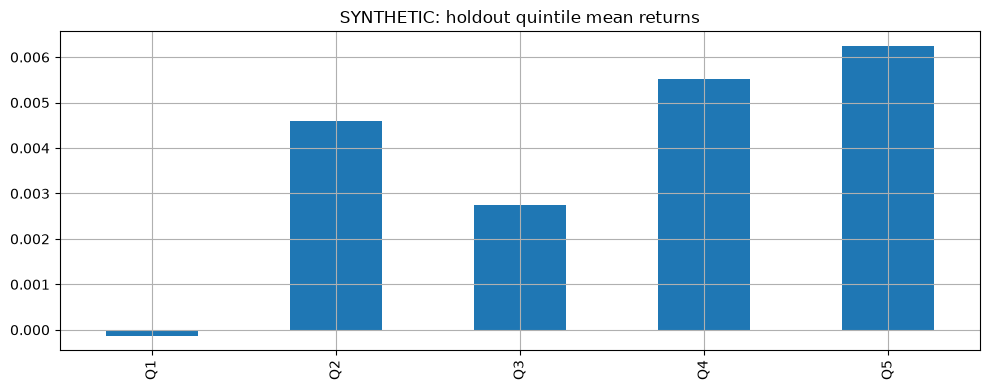

In [8]:
ic = panel.groupby('date').apply(lambda g:spearmanr(g.score,g.forward_return).statistic,include_groups=False)
group_ret = panel.groupby(['date','quintile']).forward_return.mean().unstack()
group_ret.columns = [f'Q{i}' for i in group_ret.columns]
print(pd.Series({'train_mean_rank_ic':ic.loc[train_dates].mean(),'test_mean_rank_ic':ic.loc[test_dates].mean(),
                 'test_ic_positive_share':ic.loc[test_dates].gt(0).mean()}))
print('Holdout quintile mean returns:\n',group_ret.loc[test_dates].mean())
group_ret.loc[test_dates].mean().plot.bar(title='SYNTHETIC: holdout quintile mean returns')
plt.tight_layout(); plt.savefig(OUT/'quintiles.png'); plt.show()

## 8. 分数变成权重，再进行自融资组合记账
最高20%等权，比较基准为同一合成股票池等权，不是沪深300。
$$w^{pre}_{i,t}=w^{target}_{i,t-1}(1+r_{i,t-1})/(1+r^{gross}_{p,t-1})$$
$$Turnover_t=\sum_i|w^{target}_{i,t}-w^{pre}_{i,t}|,\quad cost_t=c\cdot Turnover_t$$
本例turnover不除2；首次从现金建仓为1。长期全仓调仓的一半口径不要与这里混用。
先扣费用再持有：$$r^{net}_t=(1-cost_t)(1+\sum_iw^{target}_{i,t}r_{i,t})-1$$
小额费用模型按扣费前NAV近似交易额，忽略费用对实际成交数量的二阶调整。

In [9]:
def backtest(data, strategy='score', fee_bps=10):
    stocks = sorted(data.stock.unique())
    pre = pd.Series(0.,index=stocks)
    rows = []
    for date,g in data.groupby('date',sort=True):
        g = g.set_index('stock').reindex(stocks)
        if strategy=='equal':selected=stocks
        else:selected=g.nlargest(max(1,int(.2*len(g))),strategy).index
        target=pd.Series(0.,index=stocks);target.loc[selected]=1/len(selected)
        turnover=(target-pre).abs().sum()
        gross=float(target@g.forward_return)
        cost=turnover*fee_bps/10000
        net=(1-cost)*(1+gross)-1
        rows.append([date,g.entry_date.iloc[0],g.exit_date.iloc[0],gross,turnover,cost,net])
        pre=target*(1+g.forward_return)/(1+gross)
        assert np.isclose(target.sum(),1) and np.isclose(pre.sum(),1)
    return pd.DataFrame(rows,columns=['date','entry','exit','gross','turnover','cost','net']).set_index('date')

bt = backtest(panel)
benchmark = backtest(panel,'equal')
print(bt.head().round(5))

                entry       exit    gross  turnover     cost      net
date                                                                 
2018-01-31 2018-02-01 2018-03-01 -0.02665   1.00000  0.00100 -0.02762
2018-02-28 2018-03-01 2018-04-02  0.00141   1.51455  0.00151 -0.00011
2018-03-31 2018-04-02 2018-05-01  0.00022   1.15077  0.00115 -0.00093
2018-04-30 2018-05-01 2018-06-01  0.10286   1.27349  0.00127  0.10145
2018-05-31 2018-06-01 2018-07-02 -0.04736   1.50636  0.00151 -0.04880


## 9. 绩效：累计收益不能用cumsum替代净值
$$NAV_T=\prod_t(1+r_t),\quad CAGR=NAV_T^{12/T}-1$$
$$Vol=std(r)\sqrt{12},\quad Sharpe=mean(r-r_f)/std(r-r_f)\sqrt{12}$$
$$MDD=\min_t(NAV_t/\max_{s\leq t}NAV_s-1)$$
本例月频、无风险利率假设为0。净值高点包含初始资金1。
IR采用策略减基准的主动收益均值/跟踪误差，区别于Sharpe。
所有下列数字是合成教学输出，不作求职历史业绩引用。

                     CAGR  annual_vol  sharpe_rf0  max_drawdown
train              0.1036      0.1439      0.7576       -0.1430
holdout            0.0525      0.1354      0.4437       -0.1551
benchmark_holdout  0.0377      0.1289      0.3492       -0.1778
Holdout information ratio: 0.3781637629573985


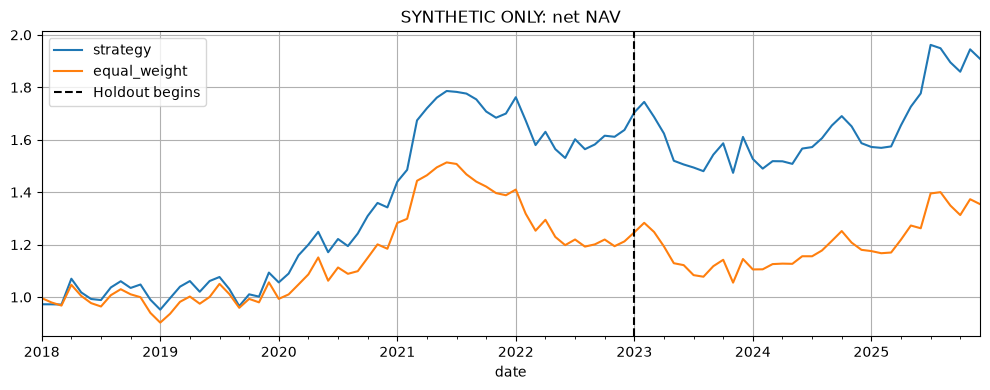

In [10]:
def performance(r):
    r=pd.Series(r).dropna()
    nav=np.r_[1.,(1+r).cumprod().values]
    return {'CAGR':nav[-1]**(12/len(r))-1,'annual_vol':r.std()*np.sqrt(12),
            'sharpe_rf0':r.mean()/r.std()*np.sqrt(12),
            'max_drawdown':(nav/np.maximum.accumulate(nav)-1).min()}

metrics=pd.DataFrame({'train':performance(bt.loc[train_dates,'net']),
                      'holdout':performance(bt.loc[test_dates,'net']),
                      'benchmark_holdout':performance(benchmark.loc[test_dates,'net'])}).T
active=bt.loc[test_dates,'net']-benchmark.loc[test_dates,'net']
print(metrics.round(4))
print('Holdout information ratio:',active.mean()/active.std()*np.sqrt(12))
pd.DataFrame({'strategy':(1+bt.net).cumprod(),'equal_weight':(1+benchmark.net).cumprod()}).plot(title='SYNTHETIC ONLY: net NAV')
plt.axvline(pd.Timestamp(test_dates[0]),color='black',linestyle='--',label='Holdout begins')
plt.legend();plt.tight_layout();plt.savefig(OUT/'nav.png');plt.show()

## 10. 费用敏感性与消融：究竟是谁在起作用
比较原始股息、行业规模中性股息、股息+质量；保持股票池与时间不变。
不是看到谁最好就重新选择后宣布测试成功；这里只展示预先定义的诊断。
此模型不含冲击、卖出税费差异、停牌、涨跌停、退市和实际分红税。

In [11]:
diagnostics=[]
for strategy in ['dy_z','dy_neutral','score']:
    for fee in [0,10,30]:
        trial=backtest(panel,strategy,fee)
        diagnostics.append({'strategy':strategy,'fee_bps_per_traded_notional':fee,
                            **performance(trial.loc[test_dates,'net'])})
diagnostics=pd.DataFrame(diagnostics)
print(diagnostics.round(4).to_string(index=False))

  strategy  fee_bps_per_traded_notional   CAGR  annual_vol  sharpe_rf0  max_drawdown
      dy_z                            0 0.0595      0.1267      0.5183       -0.1906
      dy_z                           10 0.0500      0.1266      0.4478       -0.1964
      dy_z                           30 0.0314      0.1265      0.3064       -0.2078
dy_neutral                            0 0.0444      0.1336      0.3897       -0.1503
dy_neutral                           10 0.0339      0.1336      0.3140       -0.1539
dy_neutral                           30 0.0133      0.1336      0.1626       -0.1666
     score                            0 0.0683      0.1352      0.5545       -0.1449
     score                           10 0.0525      0.1354      0.4437       -0.1551
     score                           30 0.0216      0.1356      0.2228       -0.1753


## 11. 组合暴露与简化风险模型
单只股票暴露是一行X；组合暴露是$$b_p=X_t^T w_p$$。
$$\Sigma_t=X_tF_tX_t^T+D_t,\quad\sigma_p^2=b_p^TF_tb_p+w_p^TD_tw_p$$
F是历史因子收益协方差，D是个股残差方差对角矩阵。
这里用最早48个月估计，观察第61月，确保所有估计标签都已结算。
这只是Barra-style结构演示；完整商业风险模型还有权重、约束、稳健估计和校准。
基准行业dummy+截距的参数化与完整受约束行业模型不同，不能称为复刻MSCI。

In [12]:
risk_date=pd.Timestamp(test_dates[0])
snapshot=panel.loc[panel.date.eq(risk_date)].set_index('stock').sort_index()
XR=return_design(snapshot)
chosen=snapshot.nlargest(16,'score').index
w=pd.Series(0.,index=snapshot.index);w.loc[chosen]=1/len(chosen)
assert panel.loc[panel.date.isin(train_dates[:48]),'exit_date'].max() < risk_date
F=coef.iloc[:48].cov().reindex(index=XR.columns,columns=XR.columns).to_numpy()
D=residual_matrix.iloc[:48].var().reindex(snapshot.index).to_numpy()
exposure=XR.to_numpy().T@w.to_numpy()
factor_var=float(exposure@F@exposure)
specific_var=float(np.sum(w.to_numpy()**2*D))
print(pd.Series(exposure,index=XR.columns).round(4))
print('Illustrative annual risk:',np.sqrt(12*(factor_var+specific_var)))
print('Industry weights of selected portfolio:',snapshot.loc[chosen].industry.value_counts(normalize=True).to_dict())
print('Score neutrality does not guarantee selected-portfolio neutrality.')

const        1.0000
size_z      -0.1909
sector_I1    0.2500
sector_I2    0.3750
sector_I3    0.1875
dy_z         0.8680
quality_z    0.7061
dtype: float64
Illustrative annual risk: 0.15303358923264312
Industry weights of selected portfolio: {'I2': 0.375, 'I1': 0.25, 'I3': 0.1875, 'I0': 0.1875}
Score neutrality does not guarantee selected-portfolio neutrality.


## 12. 时间序列Beta与残差动量：对应你的华泰经历
对一只股票过去120天：$$r_{i,s}=\alpha_i+\beta_i r_{m,s}+\epsilon_{i,s}$$
$$\hat\beta_i=Cov(r_i,r_m)/Var(r_m)$$（含截距OLS）。
先估计历史beta，再扣除市场解释部分，累计过去残差形成残差动量。
本例beta/alpha均shift(1)，不含当日收益；当日残差在收盘后才可得，交易须之后执行。
QTC存档代码采用无截距滚动回归sum(stock*XLK)/sum(XLK^2)，不完全等同本节公式。

In [13]:
rng=np.random.default_rng(17)
market_daily=pd.Series(rng.normal(0,.01,600))
stock_daily=.0001+1.2*market_daily+pd.Series(rng.normal(0,.008,600))
beta=stock_daily.rolling(120).cov(market_daily)/market_daily.rolling(120).var()
beta=beta.shift(1)
alpha=(stock_daily.rolling(120).mean().shift(1)-beta*market_daily.rolling(120).mean().shift(1))
resid=stock_daily-alpha-beta*market_daily
residual_momentum=resid.rolling(20).sum()
print(pd.DataFrame({'beta':beta,'alpha':alpha,'residual':resid,'residual_momentum_20d':residual_momentum}).tail().round(5))

        beta    alpha  residual  residual_momentum_20d
595  1.17592  0.00077   0.01176                0.05123
596  1.17835  0.00083  -0.00512                0.04385
597  1.17378  0.00078  -0.00499                0.03997
598  1.17808  0.00073  -0.00084                0.03312
599  1.17829  0.00065  -0.00594                0.02407


## 13. 宏观信号为何不能直接当股票横截面因子
PMI等同一国家同一天的宏观变量对所有股票可能相同，与截距共线。
可用于择时，或与不同股票的敏感度相乘形成不同横截面暴露。
Oil例子：共同信号s_t=sign(CO3-CO12)，货币各有出口/进口暴露e_i，分数=s_t*e_i。
Carry-momentum是价差相对自身历史的变化，不是股息率也不是FX利差carry。
信号观察、执行、收益区间必须分开；不能用周四信号赚上周五至本周五的已发生收益。

In [14]:
carry=pd.Series([2.,3.,4.,5.,3.,2.],name='oil_carry')
ma=carry.rolling(4).mean()
signal=pd.Series(np.where(carry>ma,1.,-1.),index=carry.index).where(ma.notna())
currency_exposure=pd.Series({'ExporterA':1/3,'ExporterB':1/3,'ExporterC':1/3,
                             'ImporterA':-1/3,'ImporterB':-1/3,'ImporterC':-1/3})
weights=signal.iloc[-1]*currency_exposure
print(pd.DataFrame({'carry':carry,'MA4':ma,'signal':signal}))
print('FX toy weights:',weights.to_dict(),'net:',weights.sum(),'gross:',weights.abs().sum())

   carry   MA4  signal
0    2.0   NaN     NaN
1    3.0   NaN     NaN
2    4.0   NaN     NaN
3    5.0  3.50     1.0
4    3.0  3.75    -1.0
5    2.0  3.50    -1.0
FX toy weights: {'ExporterA': -0.3333333333333333, 'ExporterB': -0.3333333333333333, 'ExporterC': -0.3333333333333333, 'ImporterA': 0.3333333333333333, 'ImporterB': 0.3333333333333333, 'ImporterC': 0.3333333333333333} net: -1.1102230246251565e-16 gross: 1.9999999999999998


## 14. 自动检查与导出
检查不是装饰：信息可得性、组合权重、费用、残差正交和初始回撤都应可验证。
修改未来收益标签不应改变当期分数；单次月度回测也不应使用当前forward_return选股。

In [15]:
changed=panel.copy();changed['forward_return']=999.
reprepared=prepare_exposures(changed)
assert np.allclose(reprepared.score,panel.score)
assert np.isclose(bt.turnover.iloc[0],1.)
assert (bt.net<=bt.gross+1e-12).all()
assert np.isclose(performance(pd.Series([-.1,.1]))['max_drawdown'],-.1)
assert np.isclose((1+pd.Series([.1,-.1])).prod(),.99)
assert (panel.available_date<=panel.date).all()
assert (panel.entry_date>panel.date).all()
assert (panel.exit_date>panel.entry_date).all()
altered=stock_daily.copy();altered.iloc[400]+=1
beta_altered=(altered.rolling(120).cov(market_daily)/market_daily.rolling(120).var()).shift(1)
assert np.isclose(beta.iloc[400],beta_altered.iloc[400])
assert not np.isclose(beta.iloc[401],beta_altered.iloc[401])
panel.to_csv(OUT/'synthetic_stock_month_panel.csv',index=False)
bt.to_csv(OUT/'synthetic_backtest.csv')
coef.to_csv(OUT/'synthetic_cross_section_coefficients.csv')
diagnostics.to_csv(OUT/'synthetic_ablation.csv',index=False)
summary={'data_type':'SYNTHETIC EDUCATIONAL ONLY','rows':len(panel),'months':len(ic),
         'test_rank_ic':float(ic.loc[test_dates].mean()),'metrics':metrics.to_dict(orient='index'),
         'checks_passed':['future_label_not_in_features','point_in_time','initial_entry_turnover',
                          'positive_cost_drag','compound_NAV','initial_drawdown','rolling_beta_lag'],
         'limitations':['synthetic planted signal','fixed survivor universe','no real trading restrictions',
                        'generic business-day calendar','simplified costs','not historical Huatai output']}
(OUT/'verification.json').write_text(json.dumps(summary,indent=2))
print('ALL CHECKS PASSED. Outputs in:',OUT.resolve())

ALL CHECKS PASSED. Outputs in: /LOCAL_HOME/Documents/学习/outputs/quant_factor_revision_2026-10-26/results


## 15. 复习题（先自己回答，再看讲义）
1. DY=5%为什么不是下一月预期收益5%？
2. 中性化回归与收益回归的y分别是什么？
3. 月末知道下一月收益后得到的系数，能用于月末买入吗？
4. 因子中性后选最高20%，组合一定行业中性吗？
5. 合成数据的IC显著，能写进实习业绩吗？
6. 固定80只股票换成真实CSI800需要补哪些数据？
7. Oil共同信号如何通过国家暴露产生不同头寸？
答案：分别是特征/未来结果不同；因子值/未来收益；不能；不一定；不能；
历史成分及可得时点、退市与停牌、复权/分红、交易日历与执行成本；共同信号乘异质暴露。

## 参考与边界
OLS接口：https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html
滚动回归：https://www.statsmodels.org/stable/generated/statsmodels.regression.rolling.RollingOLS.html
风险模型结构：https://docs.mosek.com/portfolio-cookbook/factormodels.html
MSCI概览：https://www.msci.com/data-and-analytics/factor-investing/equity-factor-models
以上支持方法背景，不代表本教程获得MSCI授权或复刻其模型。